# 02 — Supervisado: cómo entrenamos y evaluamos los modelos

En este notebook vamos a entrenar tres modelos y revisar qué nos dicen sus resultados. Primero armamos los datos; después comparamos dos formas de evaluarlos; por último, miramos las métricas y sus límites.

Vas a encontrar nombres usados en las prácticas (`X_train`, `X_test`, `modelo.fit`, `confusion_matrix`, `roc_curve`). Los vamos a usar dentro del problema del trabajo, no como pasos aislados.

**Recorrido:**

1. Preparar las variables de entrada (`X`) y la respuesta correcta (`y`).
2. Comparar una validación cruzada aleatoria con LOSO, que reserva un escenario completo.
3. Reducir las variables y comprobar cuáles parecen influir en el resultado.
4. Comparar Random Forest, SVM y XGBoost.
5. Leer las métricas de un escenario.
6. Cargar el modelo guardado y usarlo como en producción.


## Antes de empezar: si lo abrís en Google Colab

Este notebook vive en el repo y lee `datasets/`, `src/`, `resultados/` y `modelos/` desde la raíz del proyecto. En Colab esos archivos no existen, así que la celda de abajo clona el repo en `/content/data4cyber` y se para ahí.

**Cómo abrirlo:**

1. En Colab: *Archivo → Abrir notebook → GitHub*, pegá la URL del repo y elegí el notebook.
2. Ejecutá la primera celda. Clona el repo (una sola vez por sesión) y queda listo para correr.

Fuera de Colab la celda no hace nada.


In [1]:
# --- Preparar el entorno: solo hace algo si estás en Google Colab ---
import os
import subprocess
import sys
from pathlib import Path

REPO = "https://github.com/maxiricalde/data4cyber.git"
DESTINO = Path("/content/data4cyber")

try:
    import google.colab  # noqa: F401

    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    # CatBoost no viene preinstalado en Colab; lo instalamos una sola vez.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "catboost"], check=False)
    # Una sola vez por sesión: clonar el repo y pararse en su raíz.
    if not (DESTINO / "src" / "data.py").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, str(DESTINO)], check=True)
    os.chdir(DESTINO)
    print("proyecto en:", os.getcwd())
else:
    print("corriendo local: no hay nada que preparar")


corriendo local: no hay nada que preparar


In [2]:
import os
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    classification_report,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

# El notebook vive en notebooks/, pero los datasets y src/ están en la raíz del proyecto.
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "data.py").exists())
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ))

from src.data import build_matrices  # solo se usa para quitar la capa de anotación
from src.reduce import block_pca

pd.set_option("display.width", 140)
print("raíz del proyecto:", RAIZ)
from sklearn.model_selection import GridSearchCV, LeaveOneGroupOut, StratifiedKFold


raíz del proyecto: /media/windows/Users/pablo/Documents/UNSA/4to/MetodosCuantitativos/TPFinal


## 0. Los datos

Cada archivo CSV corresponde a un escenario. Los archivos comparten las mismas columnas: mediciones eléctricas, estado de la batería y variables del perfil del escenario (`Profile.*`). Más adelante veremos qué información aportan estas últimas y por qué hay que interpretarlas con cuidado.


In [3]:
ESCENARIOS = ("S0", "S1", "S1alt", "S2", "S3", "S4", "S5", "S6")

frames = pd.concat(
    [pd.read_csv(f"datasets/dataset{nombre}.csv").assign(scenario=nombre) for nombre in ESCENARIOS],
    ignore_index=True,
)

print("filas totales:", frames.shape)
print(frames["scenario"].value_counts().sort_index())

filas totales: (14354, 157)
scenario
S0       1798
S1       1798
S1alt    1792
S2       1768
S3       1800
S4       1798
S5       1800
S6       1800
Name: count, dtype: int64


`build_matrices` separa las columnas que usaremos para aprender de las anotaciones que sirven para describir los datos. Entre las que se apartan están `attack_active`, `attack_phase`, `timestamp` y el precio de MQTT; el precio se excluye porque puede revelar directamente la etiqueta del ataque.

La función devuelve:

- `X`: las 139 variables de entrada (también llamadas *features*).
- `y_binary`: la respuesta correcta de cada fila: `1` significa ataque y `0`, benigno.
- `scenario`: el escenario al que pertenece cada fila.


In [4]:
m = build_matrices(frames)

X_crudo = m.X
y = m.y_binary
escenario = m.scenario

print("X:", X_crudo.shape)
print(f"ataques: {int(y.sum()):,} ({100 * y.mean():.1f} %)")

X: (14354, 139)
ataques: 7,586 (52.8 %)


### Tres ayudantes que vamos a reutilizar

Estas funciones evitan repetir pasos y dejan visible qué hacemos en cada entrenamiento:

1. `crear_modelo` prepara un clasificador sin entrenarlo. Usamos valores de configuración fijos; no buscamos la combinación óptima.
2. `crear_pipeline` une tres pasos: completar valores faltantes, escalar las variables y entrenar el modelo. Cada paso se ajusta solo con los datos de entrenamiento de ese fold. Si usáramos también el test para ajustar el escalado, estaríamos filtrando información de la prueba.
3. `pesos_balanceados` da más peso a la clase menos frecuente durante el entrenamiento. Así el modelo no puede obtener un buen resultado simplemente favoreciendo la clase que aparece más.


In [5]:
ETIQUETAS = {"rf": "Random Forest", "svm": "SVM (RBF)", "xgb": "XGBoost", "catboost": "CatBoost"}


def crear_modelo(nombre, semilla=42):
    """Clasificador sin entrenar. Los hiperparámetros quedan fijos a propósito."""
    if nombre == "rf":
        return RandomForestClassifier(
            n_estimators=300, min_samples_leaf=2, n_jobs=-1, random_state=semilla
        )
    if nombre == "svm":
        return SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=1000, random_state=semilla)
    if nombre == "xgb":
        return XGBClassifier(
            n_estimators=300,
            max_depth=4,
            learning_rate=0.1,
            subsample=0.8,
            colsample_bytree=0.8,
            tree_method="hist",
            eval_metric="logloss",
            n_jobs=-1,
            random_state=semilla,
        )
    if nombre == "catboost":
        return CatBoostClassifier(
            iterations=300, depth=6, learning_rate=0.1, random_seed=semilla, verbose=0
        )
    raise ValueError(f"modelo desconocido: {nombre}")


def crear_pipeline(modelo):
    """Imputar -> escalar -> modelo, como una sola unidad."""
    return Pipeline(
        [
            ("imputar", SimpleImputer(strategy="median")),
            ("escalar", StandardScaler()),
            ("modelo", modelo),
        ]
    )


def pesos_balanceados(y):
    """Peso inverso a la frecuencia: cada clase aporta lo mismo al ajuste."""
    clases, cuentas = np.unique(y, return_counts=True)
    if len(clases) < 2:
        return np.ones(len(y))
    pesos = {clase: len(y) / (len(clases) * cuenta) for clase, cuenta in zip(clases, cuentas)}
    return np.array([pesos[valor] for valor in y])


def score_del_modelo(modelo, X_test):
    """Score continuo de la clase ataque, para AUC y curvas.

    Random Forest y XGBoost tienen predict_proba. SVM con probability=False no;
    para SVM se usa decision_function, que ordena igual.
    """
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X_test)[:, 1]
    return modelo.decision_function(X_test)


def recall_con_fpr(y_true, score, fpr_objetivo):
    """TPR leyendo la curva ROC en una tasa fija de falsos positivos."""
    fpr, tpr, _ = roc_curve(y_true, score)
    return float(np.interp(fpr_objetivo, fpr, tpr))

## 1. Por qué comparamos con LOSO

En una división aleatoria, algunas filas muy parecidas pueden quedar en entrenamiento y otras en prueba. Eso es un problema acá porque las mediciones se registran cada segundo: dos filas consecutivas suelen parecerse mucho. Además, filas del mismo episodio y del mismo escenario pueden terminar a ambos lados de la división.

Por eso también usamos **LOSO** (*Leave-One-Scenario-Out*): en cada ronda dejamos un escenario entero para la prueba y entrenamos con los demás. Así medimos mejor si el modelo se traslada a un escenario que no vio durante el entrenamiento.

LOSO reduce la fuga causada por repartir filas vecinas del mismo episodio entre entrenamiento y prueba. **No elimina por sí solo el confusor temporal**: el momento en que ocurre el ataque todavía puede estar relacionado con las variables medidas.

Antes de separar los datos calculamos un rango móvil de 120 segundos para cada variable. Es causal: para calcular el valor de una fila usa solo datos anteriores de ese mismo escenario, nunca datos futuros.


In [6]:
def rango_movil(X, escenario, ventana=120):
    '''Máximo - mínimo en una ventana móvil, dentro de cada escenario.

    Una fila es un segundo. La ventana de 120 s mide volatilidad local y saca la
    tendencia lenta. Las primeras filas usan una ventana más corta (min_periods=1).
    '''
    ventana_rodante = X.groupby(escenario).rolling(ventana, min_periods=1)
    maximo = ventana_rodante.max().reset_index(level=0, drop=True)
    minimo = ventana_rodante.min().reset_index(level=0, drop=True)
    return (maximo - minimo).reindex(X.index)


X = rango_movil(X_crudo, escenario)
print("features:", X.shape[1], "| filas:", X.shape[0])

features: 139 | filas: 14354


### 1.1 Validación cruzada aleatoria, 8 folds

El primer punto de comparación es una validación cruzada común: se mezclan **las filas** al azar, se reparten en 8 partes y cada parte sirve una vez como prueba mientras el modelo entrena con las otras 7.

Usamos 8 folds a propósito, para que la comparación tenga sentido: el mismo número de rondas y la misma fracción de entrenamiento que LOSO (7 de 8, es decir 87,5 %). Así la única diferencia entre las dos evaluaciones es **qué se deja afuera**: filas sueltas o un escenario completo.

Estratificamos por etiqueta, así que las 8 rondas tienen ataques y las métricas se pueden calcular en todas.

Este esquema es familiar, pero acá puede dar una imagen demasiado optimista: una fila de prueba puede tener filas vecinas casi iguales dentro del entrenamiento.

In [7]:
filas = []
cortes = StratifiedKFold(n_splits=8, shuffle=True, random_state=0)

for numero, (indices_train, indices_test) in enumerate(cortes.split(X, y), start=1):
    X_train, X_test = X.iloc[indices_train], X.iloc[indices_test]
    y_train, y_test = y.iloc[indices_train], y.iloc[indices_test]

    modelo = crear_pipeline(crear_modelo("rf"))
    modelo.fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))

    pred_test = modelo.predict(X_test)
    score_test = score_del_modelo(modelo, X_test)

    filas.append(
        {
            "fold": numero,
            "exactitud": accuracy_score(y_test, pred_test),
            "AUC": roc_auc_score(y_test, score_test),
            "recall@5%": recall_con_fpr(y_test, score_test, 0.05),
        }
    )

cv_aleatoria = pd.DataFrame(filas)
display(cv_aleatoria.round(4))
print(
    "AUC medio:", round(cv_aleatoria.AUC.mean(), 4),
    "| desvío entre folds:", round(cv_aleatoria.AUC.std(), 4),
)

,fold,exactitud,AUC,recall@5%
0,1,0.9983,1.0000,1.0000
1,2,0.9967,1.0000,1.0000
2,3,0.9978,1.0000,1.0000
3,4,0.9978,0.9993,0.9989
4,5,0.9983,1.0000,1.0000
5,6,0.9983,0.9999,1.0000
6,7,0.9972,1.0000,1.0000
7,8,0.9972,1.0000,1.0000


AUC medio: 0.9999 | desvío entre folds: 0.0002


### 1.2 LOSO: dejar un escenario afuera

Cada fold es una ronda de evaluación. En cada ronda, el modelo entrena con siete escenarios y se prueba con el octavo, que quedó completamente afuera.

`S0` contiene solo filas benignas. Como no hay ataques para comparar, no se puede calcular su AUC ni su recall; por eso no entra en el promedio de esas métricas.


In [8]:
filas = []
for retenido in ESCENARIOS:
    test = (escenario == retenido).to_numpy()
    train = ~test

    X_train, X_test = X.loc[train], X.loc[test]
    y_train = y.loc[train]
    y_test = y.loc[test].to_numpy()

    modelo = crear_pipeline(crear_modelo("rf"))
    modelo.fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))

    score_test = score_del_modelo(modelo, X_test)
    dos_clases = len(np.unique(y_test)) == 2

    filas.append(
        {
            "fold": retenido,
            "filas": int(test.sum()),
            "ataques": int(y_test.sum()),
            "AUC": roc_auc_score(y_test, score_test) if dos_clases else np.nan,
            "recall@5%": recall_con_fpr(y_test, score_test, 0.05) if dos_clases else np.nan,
        }
    )

loso_base = pd.DataFrame(filas)
display(loso_base.round(3))
print("AUC medio (folds con ataque):", round(loso_base.AUC.mean(), 3))

,fold,filas,ataques,AUC,recall@5%
0,S0,1798,0,NaN,NaN
1,S1,1798,913,0.901,0.527
2,S1alt,1792,910,0.862,0.327
3,S2,1768,903,0.950,0.698
4,S3,1800,912,0.910,0.799
5,S4,1798,1257,0.986,0.955
6,S5,1800,1341,0.913,0.216
7,S6,1800,1350,0.858,0.574


AUC medio (folds con ataque): 0.912


### 1.3 Qué cambia entre las dos evaluaciones

El modelo, las 139 variables y los pasos de preprocesamiento son los mismos. Lo único que cambia es cómo se separan las filas entre entrenamiento y prueba: al azar o por escenario completo.


In [9]:
comparacion = pd.DataFrame(
    {
        "partición": [
            "CV aleatoria, 8 folds (mismas filas)",
            "LOSO, 8 folds (escenario entero)",
        ],
        "AUC": [cv_aleatoria.AUC.mean(), loso_base.AUC.mean()],
        "recall@5% FPR": [cv_aleatoria["recall@5%"].mean(), loso_base["recall@5%"].mean()],
        "exactitud": [cv_aleatoria.exactitud.mean(), np.nan],
    }
)
display(comparacion.round(4))

,partición,AUC,recall@5% FPR,exactitud
0,"CV aleatoria, 8 folds (mismas filas)",0.9999,0.9999,0.9977
1,"LOSO, 8 folds (escenario entero)",0.9116,0.5850,NaN


El AUC de la validación cruzada aleatoria **no significa que el modelo generalice así de bien**. La prueba contiene filas muy parecidas a otras que el modelo ya vio al entrenar, por eso el resultado está contaminado.

La comparación está armada para que no quede duda: las dos evaluaciones usan el mismo modelo, las mismas 139 variables, 8 folds y la misma fracción de entrenamiento. Lo único que cambia es la unidad que se deja afuera. Con filas sueltas el AUC es 0,9999 y el desvío entre folds es 0,0002: no es una partición afortunada, es sistemáticamente casi perfecto. Con escenarios enteros el AUC baja a 0,912 y el recall en el punto de 5 % de falsas alarmas cae de 0,9999 a 0,585.

LOSO es una prueba más exigente y apropiada para medir transferencia entre escenarios, pero no resuelve el confusor temporal que mencionamos antes. Por eso vamos a leer sus resultados junto con los controles de las secciones siguientes, no como prueba definitiva de detección independiente del tiempo.

## 2. Cómo elegimos una receta más pequeña

La receta `physical_corr` baja de 139 variables a alrededor de 15 en **tres pasos**, y cada paso se puede contar por separado:

| Paso | Qué hace | Columnas |
|---|---|---|
| 0 | matriz de entrada | 139 |
| 1 | selección por dominio físico | 29 |
| 2 | promedio de las 5 `freq` | 25 |
| 3 | filtro de correlación (\|r\| > 0,95) | 15 |

Los pasos 1 y 2 son siempre iguales: dependen de los nombres de las columnas, no de los datos. El paso 3 se ajusta **dentro de cada fold**, así que su número oscila entre 15 y 16 según qué escenario quede afuera.

La celda siguiente define las tres funciones; la de más abajo muestra la escalera calculada sobre estos datos.

In [10]:
def columnas_fisicas(X):
    '''Selección por dominio: qué columnas tienen sentido físico comparables.'''
    columnas = []
    for columna in X.columns:
        equipo, _, senal = columna.partition(".")
        if equipo.endswith("Meter") and senal in ("cos_phi1", "cos_phi2", "cos_phi3", "freq"):
            columnas.append(columna)
        elif equipo in ("Battery-SOC-Reference", "Battery-SOC-Reported", "Profile"):
            columnas.append(columna)
    return columnas


def receta_fisica(X):
    '''Aplica la selección por dominio y promedia SOLO la frecuencia.'''
    seleccion = X[columnas_fisicas(X)].copy()
    frecuencias = [
        c for c in X.columns if c.split(".")[0].endswith("Meter") and c.endswith(".freq")
    ]
    seleccion = seleccion.drop(columns=[c for c in frecuencias if c in seleccion.columns])
    seleccion["freq"] = X[frecuencias].mean(axis=1)
    return seleccion


def filtro_correlacion(X_entrenamiento, umbral=0.95):
    '''De cada par con |r| > 0.95 deja una columna: la primera en el orden.'''
    correlacion = X_entrenamiento.corr().abs()
    triangulo_superior = correlacion.where(np.triu(np.ones(correlacion.shape, dtype=bool), k=1))
    return [c for c in X_entrenamiento.columns if not (triangulo_superior[c] > umbral).any()]


seleccion_dominio = columnas_fisicas(X)
X_fisico = receta_fisica(X)

print(f"139 features -> {len(seleccion_dominio)} tras la selección por dominio")
print(f"{len(seleccion_dominio)} -> {X_fisico.shape[1]} tras promediar las 5 frecuencias")

139 features -> 29 tras la selección por dominio
29 -> 25 tras promediar las 5 frecuencias


In [11]:
# La escalera completa, contada paso por paso.
# El paso 3 se ajusta solo con el entrenamiento del fold (acá: todo menos S0).
entreno_sin_s0 = (escenario != "S0").to_numpy()

escalera = pd.DataFrame(
    [
        ("0. matriz de entrada", X.shape[1]),
        ("1. selección por dominio", len(seleccion_dominio)),
        ("2. tras promediar freq", X_fisico.shape[1]),
        ("3. tras filtro de correlación", len(filtro_correlacion(X_fisico.loc[entreno_sin_s0]))),
    ],
    columns=["paso", "columnas"],
)
display(escalera)

,paso,columnas
0,0. matriz de entrada,139
1,1. selección por dominio,29
2,2. tras promediar freq,25
3,3. tras filtro de correlación,15


**Qué quita cada paso.**

- **Paso 1: 139 → 29.** Sobreviven las columnas cuyo valor es comparable entre equipos: los tres factores de potencia `cos_phi1..3` de los cinco medidores, las cinco `freq`, el SOC de la batería (medido y reportado) y las siete `Profile.*`. Quedan afuera 110 columnas —potencias, corrientes, tensiones, ángulos y temperaturas de cada equipo— no porque estorben, sino porque cada medidor observa una parte distinta de la planta: un kilowatt de `BSS` no es un kilowatt de `Load-B`.
- **Paso 2: 29 → 25.** Las cinco `freq` son la misma red vista por cinco sensores redundantes (difieren en 0,001 Hz y su \|r\| cruzada está entre 0,97 y 0,996). Se promedian en una sola columna. Es el **único** promedio de la receta: `cos_phi` se mantiene por medidor porque fuentes y cargas tienen signos opuestos, y promediarlas daría un índice, no una medición.
- **Paso 3: 25 → 15.** Si dos de las 25 tienen \|r\| > 0,95 en el entrenamiento, se conserva una. Esta parte no mira qué mide cada columna, solo cuánto se repiten.

El paso 3 se vuelve a ajustar en cada fold usando solo el entrenamiento. Por eso la cantidad final puede variar entre 15 y 16 columnas: el escenario reservado no participa en la selección.

Veamos el caso concreto: ajustamos con todos los escenarios menos `S0` y revisamos qué columnas quedan.

In [12]:
columnas_s0 = filtro_correlacion(X_fisico.loc[(escenario != "S0").to_numpy()])
print(f"{len(columnas_s0)} columnas con S0 afuera:")
for columna in columnas_s0:
    print(" ", columna)

15 columnas con S0 afuera:
  BSS-Inverter-AC-Meter.cos_phi1
  Battery-SOC-Reference.soc_value
  Battery-SOC-Reported.soc_value
  Load-A-AC-Meter.cos_phi1
  Load-A-AC-Meter.cos_phi2
  Load-B-AC-Meter.cos_phi1
  Load-B-AC-Meter.cos_phi2
  PV-Inverter-AC-Meter.cos_phi1
  Profile.ambient_temperature
  Profile.load1_kw
  Profile.load2_kw
  Profile.pv_active_kw
  Profile.total_irradiance
  Substation-AC-Meter.cos_phi1
  freq


Ahora repetimos LOSO con la receta reducida. Además de las métricas, guardamos para cada fold la respuesta real, la predicción y el puntaje del modelo. Esos valores nos permiten estudiar con más detalle las métricas en la sección 4.


In [13]:
def loso_receta_reducida(nombre_modelo, guardar_detalle=False):
    """LOSO completo con la receta física; el filtro de correlación se ajusta por fold."""
    filas = []
    detalle = {}

    for retenido in ESCENARIOS:
        test = (escenario == retenido).to_numpy()
        train = ~test

        # El filtro de correlación se ajusta SOLO con el entrenamiento del fold.
        columnas = filtro_correlacion(X_fisico.loc[train])
        X_train, X_test = X_fisico.loc[train, columnas], X_fisico.loc[test, columnas]
        y_train = y.loc[train]
        y_test = y.loc[test].to_numpy()

        modelo = crear_pipeline(crear_modelo(nombre_modelo))
        modelo.fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))

        pred_test = modelo.predict(X_test)
        score_test = score_del_modelo(modelo, X_test)
        dos_clases = len(np.unique(y_test)) == 2

        if guardar_detalle:
            detalle[retenido] = {
                "y_test": y_test,
                "pred_test": pred_test,
                "score_test": score_test,
                "exactitud_train": accuracy_score(y_train, modelo.predict(X_train)),
                "modelo": modelo,
            }
        filas.append(
            {
                "fold": retenido,
                "features": len(columnas),
                "AUC": roc_auc_score(y_test, score_test) if dos_clases else np.nan,
                "recall_5": recall_con_fpr(y_test, score_test, 0.05) if dos_clases else np.nan,
                "especificidad_S0": (
                    float((pred_test == 0).mean()) if retenido == "S0" else np.nan
                ),
            }
        )

    return pd.DataFrame(filas), detalle


loso_reducida, detalle_reducida = loso_receta_reducida("rf", guardar_detalle=True)
display(loso_reducida.round(3))
print("AUC medio (folds con ataque):", round(loso_reducida.AUC.mean(), 3))

,fold,features,AUC,recall_5,especificidad_S0
0,S0,15,NaN,NaN,0.996
1,S1,15,0.983,0.972,NaN
2,S1alt,16,0.958,0.919,NaN
3,S2,15,0.935,0.427,NaN
4,S3,15,0.933,0.485,NaN
5,S4,16,0.967,0.838,NaN
6,S5,16,0.891,0.113,NaN
7,S6,15,0.932,0.707,NaN


AUC medio (folds con ataque): 0.943


### 2.1 Comparar la receta base con la reducida

Las dos evaluaciones usan el mismo modelo, el mismo preprocesamiento y la misma separación LOSO. La diferencia es el conjunto de variables: 139 en la receta base y unas 15 en la reducida.


In [14]:
comparacion = loso_base[["fold", "AUC"]].rename(columns={"AUC": "base_139"}).merge(
    loso_reducida[["fold", "features", "AUC"]].rename(columns={"AUC": "reducida"}),
    on="fold",
)
comparacion["delta"] = comparacion["reducida"] - comparacion["base_139"]
display(comparacion.round(3))

resumen = pd.DataFrame(
    {
        "receta": ["base", "physical_corr"],
        "features": [X.shape[1], loso_reducida.features.mean()],
        "AUC medio": [loso_base.AUC.mean(), loso_reducida.AUC.mean()],
        "recall@5% medio": [loso_base["recall@5%"].mean(), loso_reducida.recall_5.mean()],
    }
)
display(resumen.round(3))

,fold,base_139,features,reducida,delta
0,S0,NaN,15,NaN,NaN
1,S1,0.901,15,0.983,0.082
2,S1alt,0.862,16,0.958,0.095
3,S2,0.950,15,0.935,-0.015
4,S3,0.910,15,0.933,0.022
5,S4,0.986,16,0.967,-0.020
6,S5,0.913,16,0.891,-0.022
7,S6,0.858,15,0.932,0.074


,receta,features,AUC medio,recall@5% medio
0,base,139.000,0.912,0.585
1,physical_corr,15.375,0.943,0.637


La receta reducida usa 15–16 columnas en vez de 139. En esta ejecución, el AUC promedio pasa de 0,912 a 0,943 y el recall medio en el punto de 5 % de falsas alarmas, de 0,585 a 0,637. El cambio no es igual en todos los escenarios: por eso también mostramos el detalle por fold.

Esto indica que una lista más corta de variables puede conservar el desempeño medido. **No demuestra por sí solo que el modelo haya aprendido una señal de ataque independiente del tiempo.** Para mirar qué variables sostienen ese resultado, la sección siguiente prueba una selección distinta: guiada por la importancia de Random Forest en vez del dominio físico.


### 2.2 Selección por importancia de Random Forest

In [15]:
filas_importancia = []
importancias_por_fold = []

for retenido in ESCENARIOS:
    test = (escenario == retenido).to_numpy()
    train = ~test

    X_train, X_test = X.loc[train], X.loc[test]
    y_train = y.loc[train]
    y_test = y.loc[test].to_numpy()
    pesos_train = pesos_balanceados(y_train)

    # El primer Random Forest aprende el ranking usando solo el entrenamiento.
    modelo_ranking = crear_pipeline(crear_modelo("rf"))
    modelo_ranking.fit(X_train, y_train, modelo__sample_weight=pesos_train)

    importancia = modelo_ranking.named_steps["modelo"].feature_importances_
    orden = np.argsort(importancia)[::-1]
    columnas_top15 = X_train.columns[orden[:15]].tolist()

    # Guardamos el ranking de cada fold para ver qué variables se repiten.
    seleccionadas = set(columnas_top15)
    for columna, valor in zip(X_train.columns, importancia):
        importancias_por_fold.append(
            {
                "fold": retenido,
                "feature": columna,
                "importancia": valor,
                "seleccionada_top15": columna in seleccionadas,
            }
        )

    # Volvemos a entrenar usando solo las 15 variables seleccionadas.
    modelo_top15 = crear_pipeline(crear_modelo("rf"))
    modelo_top15.fit(
        X_train[columnas_top15], y_train, modelo__sample_weight=pesos_train
    )
    score_test = score_del_modelo(modelo_top15, X_test[columnas_top15])
    dos_clases = len(np.unique(y_test)) == 2

    filas_importancia.append(
        {
            "fold": retenido,
            "features": len(columnas_top15),
            "AUC": roc_auc_score(y_test, score_test) if dos_clases else np.nan,
            "recall@5%": (
                recall_con_fpr(y_test, score_test, 0.05) if dos_clases else np.nan
            ),
        }
    )

loso_importancia = pd.DataFrame(filas_importancia)
display(loso_importancia.round(3))
print("AUC medio (folds con ataque):", round(loso_importancia.AUC.mean(), 3))

# Una variable puede subir o bajar en el ranking entre folds; mostramos ambas cosas.
tabla_importancia = (
    pd.DataFrame(importancias_por_fold)
    .groupby("feature")
    .agg(
        importancia_media=("importancia", "mean"),
        folds_en_top15=("seleccionada_top15", "sum"),
    )
    .sort_values(["folds_en_top15", "importancia_media"], ascending=False)
)
display(tabla_importancia.head(15).round(4))

resumen_seleccion = pd.DataFrame(
    {
        "método": ["base (139)", "importancia RF (15)", "física + correlación"],
        "features": [139, loso_importancia.features.mean(), loso_reducida.features.mean()],
        "AUC medio": [loso_base.AUC.mean(), loso_importancia.AUC.mean(), loso_reducida.AUC.mean()],
        "recall@5% medio": [
            loso_base["recall@5%"].mean(),
            loso_importancia["recall@5%"].mean(),
            loso_reducida.recall_5.mean(),
        ],
    }
)
display(resumen_seleccion.round(3))


,fold,features,AUC,recall@5%
0,S0,15,NaN,NaN
1,S1,15,0.901,0.599
2,S1alt,15,0.833,0.042
3,S2,15,0.949,0.756
4,S3,15,0.940,0.726
5,S4,15,0.967,0.912
6,S5,15,0.898,0.075
7,S6,15,0.733,0.363


AUC medio (folds con ataque): 0.889


,importancia_media,folds_en_top15
feature,,
BSS-Inverter-AC-Meter.iln3,0.0378,8
BSS-Inverter-AC-Meter.iln2,0.0346,8
BSS-Inverter-AC-Meter.iln1,0.0335,8
BSS-Inverter-AC-Meter.s_sum3,0.0322,8
BSS-Inverter-AC-Meter.sln3,0.0297,8
BSS-Inverter-AC-Meter.sln2,0.0287,8
BSS-Inverter-AC-Meter.i_sum3,0.0277,8
Profile.load2_kw,0.0411,7
Profile.load1_kw,0.0282,7


,método,features,AUC medio,recall@5% medio
0,base (139),139.000,0.912,0.585
1,importancia RF (15),15.000,0.889,0.496
2,física + correlación,15.375,0.943,0.637


### Qué resultado dio esta selección

Con las 15 variables elegidas por importancia, el AUC medio fue 0,889 y el recall@5% fue 0,496. En esta ejecución queda por debajo de la receta física con filtro de correlación (AUC 0,943; recall@5% 0,637) y del modelo base de 139 variables (AUC 0,912; recall@5% 0,585).

Esto no invalida el método: muestra que seleccionar variables solo por la importancia de un Random Forest no garantiza mejores resultados. Además, el conjunto elegido cambia entre folds, así que conviene mirar tanto la métrica como la estabilidad de las variables seleccionadas.


### ¿Y RFE? Eliminación recursiva sobre la receta física

`RFE` parte de un conjunto y, en cada vuelta, elimina las variables menos importantes, reajustando el modelo cada vez. Acá lo corremos sobre la receta física: de las 25 columnas elimina de a una hasta quedar 15, y repite el ajuste dentro de cada fold, igual que el filtro de correlación.

**Ojo con el perfil.** RFE conserva casi siempre las columnas de `Profile.*` (mirá la columna `de_perfil`). No es casualidad: esas variables separan el escenario, y RFE se premia por separar la etiqueta. Por eso su AUC se acerca al de la receta física sin aportar una selección más limpia.

In [16]:
from sklearn.feature_selection import RFE

# RFE: eliminar recursivamente de las 25 columnas físicas hasta quedar 15.
# El selector se reajusta en cada fold, con el entrenamiento solamente.
filas_rfe = []
for retenido in ESCENARIOS:
    test = (escenario == retenido).to_numpy()
    train = ~test
    X_train, X_test = X_fisico.loc[train], X_fisico.loc[test]
    y_train = y.loc[train]
    y_test = y.loc[test].to_numpy()

    selector = RFE(
        estimator=crear_pipeline(crear_modelo("rf")),
        n_features_to_select=15,
        step=1,
        importance_getter="named_steps.modelo.feature_importances_",
    ).fit(X_train, y_train, modelo__sample_weight=pesos_balanceados(y_train))
    columnas_rfe = X_train.columns[selector.support_]

    modelo = crear_pipeline(crear_modelo("rf"))
    modelo.fit(X_train[columnas_rfe], y_train, modelo__sample_weight=pesos_balanceados(y_train))

    pred_test = modelo.predict(X_test[columnas_rfe])
    score_test = score_del_modelo(modelo, X_test[columnas_rfe])
    dos_clases = len(np.unique(y_test)) == 2

    filas_rfe.append(
        {
            "fold": retenido,
            "features": len(columnas_rfe),
            "AUC": roc_auc_score(y_test, score_test) if dos_clases else np.nan,
            "recall_5": recall_con_fpr(y_test, score_test, 0.05) if dos_clases else np.nan,
            "recall_1": recall_con_fpr(y_test, score_test, 0.01) if dos_clases else np.nan,
            "especificidad_S0": float((pred_test == 0).mean()) if retenido == "S0" else np.nan,
            "de_perfil": sum(columna.startswith("Profile.") for columna in columnas_rfe),
        }
    )

loso_rfe = pd.DataFrame(filas_rfe)
display(loso_rfe.round(3))
print("AUC medio (folds con ataque):", round(loso_rfe.AUC.mean(), 3))
print("columnas de Profile.* por fold:", loso_rfe.de_perfil.tolist())

,fold,features,AUC,recall_5,recall_1,especificidad_S0,de_perfil
0,S0,15,NaN,NaN,NaN,1.0,6
1,S1,15,0.973,0.804,0.705,NaN,7
2,S1alt,15,0.960,0.919,0.679,NaN,7
3,S2,15,0.926,0.398,0.364,NaN,7
4,S3,15,0.932,0.496,0.158,NaN,7
5,S4,15,0.976,0.956,0.956,NaN,7
6,S5,15,0.904,0.253,0.248,NaN,7
7,S6,15,0.963,0.850,0.703,NaN,7


AUC medio (folds con ataque): 0.948
columnas de Profile.* por fold: [6, 7, 7, 7, 7, 7, 7, 7]


### 2.3 ¿Y si usamos PCA? Lo medimos y perdió

Antes de mirar los bloques, tres resultados que después reúne la tabla comparativa del cierre de la sección:

- **El filtro de correlación gana**: `corr` conserva 55 columnas y sube el AUC a 0,941, por encima de las 139 originales (0,912).
- **PCA pierde**: con 20,8 componentes el AUC cae a 0,873. No es un problema de cantidad: con 100 componentes (de 139) el AUC solo llega a 0,885.
- **Agrupar por correlación y aplicar PCA dentro de cada grupo** es lo mejor medido: `block_pca` llega a 0,952 y sube el recall al 5 % de falsos positivos de 0,637 a 0,752.

Antes de mirar los bloques, vale la pena entender por qué PCA global falla.

In [17]:
from sklearn.decomposition import PCA

# Usamos solo el entrenamiento (S0 afuera) y lo imputamos con su propia mediana.
filas_entreno = (escenario != "S0").to_numpy()
X_entreno = X.loc[filas_entreno].copy()
X_entreno = X_entreno.fillna(X_entreno.median())
X_estandar = StandardScaler().fit_transform(X_entreno)

# 1. ¿Cuántas componentes retienen el 95 % de la varianza?
pca_95 = PCA(n_components=0.95, random_state=42).fit(X_estandar)
print("componentes que retienen el 95 % de la varianza:", pca_95.n_components_)

# 2. ¿Cuánto de la diferencia ataque-vs-normal queda en esas componentes?
pca_completa = PCA(random_state=42).fit(X_estandar)
y_entreno = y.loc[filas_entreno]
direccion = X_estandar[y_entreno == 1].mean(axis=0) - X_estandar[y_entreno == 0].mean(axis=0)
peso = (pca_completa.components_ @ direccion) ** 2
cuota = peso.cumsum() / peso.sum()
print("cuota de esa diferencia en las primeras 21 componentes:", round(cuota[20], 3))

componentes que retienen el 95 % de la varianza: 21
cuota de esa diferencia en las primeras 21 componentes: 0.997


**PCA no está perdiendo información.** El 99,7 % de la dirección que separa ataque de normal cae dentro de las primeras 21 componentes. Entonces, ¿por qué baja el AUC?

Porque un árbol de decisión corta **una variable a la vez**. Cada componente de PCA es una mezcla de las 139 columnas: un umbral sobre una componente no equivale a "la corriente de la subestación bajó", que es lo que el árbol necesita expresar. Para reconstruir esa regla hacen falta muchos cortes encadenados y el modelo generaliza peor.

Dos mediciones apoyan esta explicación (mismo protocolo, corridas aparte para no demorar el notebook):

- PCA con 21, 55 y 100 componentes da 0,873, 0,891 y 0,885. Si fuera falta de información, más componentes deberían recuperar el AUC; no lo hacen.
- Con regresión logística, que no hace cortes y es indiferente a la rotación, la diferencia casi desaparece: 0,787 con el filtro de correlación contra 0,764 con PCA.

La conclusión es que PCA conserva los datos pero los deja en una forma incómoda para el modelo. La alternativa es no mezclar todo: agrupar primero las variables que miden lo mismo y comprimir dentro de cada grupo.

### 2.4 La alternativa que funciona: agrupar por correlación (VARCLUS)

In [18]:
from scipy.cluster.hierarchy import fcluster, linkage
from scipy.spatial.distance import squareform

# PASO 1 - Parecido entre columnas.
# X_entreno.corr() arma la matriz 139x139 de correlaciones de Pearson.
# .abs() porque r = -0,98 y r = +0,98 son igual de redundantes: una columna es
# la otra con el signo dado vuelta, y para resumir interesa el vinculo, no la
# direccion. .values la deja como arreglo numerico.
correlacion = X_entreno.corr().abs().values

# PASO 2 - De parecido a distancia.
# 1 - |r| va de 0 (columnas identicas) a 1 (sin relacion). Es la metrica que
# sabe leer el agrupamiento jerarquico.
distancia = 1 - correlacion
# La diagonal tiene que dar 0 exacto: una columna contra si misma.
np.fill_diagonal(distancia, 0)
# Promediar con la traspuesta fuerza la simetria. Sin esto alcanza un error de
# coma flotante del orden de 1e-16 para que squareform() rechace la matriz.
distancia = (distancia + distancia.T) / 2

# PASO 3 - Arbol jerarquico.
# linkage() fusiona de a dos los grupos mas cercanos hasta que queda uno solo y
# guarda en que orden lo hizo. "average" mide la distancia entre dos grupos como
# el promedio de todos sus pares: no se deja arrastrar por un unico vinculo
# extremo, como haria "single".
arbol = linkage(squareform(distancia, checks=False), method="average")

# PASO 4 - Corte.
# t = 0.3 deja juntas a las columnas cuya distancia promedio es <= 0,3, o sea
# con |r| promedio >= 0,7. Subir el corte achica los bloques y la tecnica se
# parece cada vez mas al filtro de correlacion; bajarlo los agranda.
etiquetas = fcluster(arbol, t=0.3, criterion="distance")
bloques = pd.Series(etiquetas, index=X_entreno.columns)

print("bloques encontrados:", bloques.nunique())
print("columnas por bloque (las 10 más grandes):")
print(bloques.value_counts().head(10))

bloques encontrados: 28
columnas por bloque (las 10 más grandes):
13    22
15    19
17    17
11    12
5      7
26     7
12     7
2      5
10     4
9      4
Name: count, dtype: int64


In [19]:
# Los tres casos que conviene mirar por separado: el bloque mas grande, el
# bloque de frecuencias y las columnas que no se agruparon con ninguna.

# El bloque más grande.
etiqueta_mas_grande = bloques.value_counts().index[0]
columnas_mas_grande = list(bloques[bloques == etiqueta_mas_grande].index)
print(f"bloque más grande ({len(columnas_mas_grande)} columnas):")
print(columnas_mas_grande)

# El bloque que junta las cinco frecuencias.
for etiqueta in bloques.unique():
    columnas = list(bloques[bloques == etiqueta].index)
    if all(columna.endswith(".freq") for columna in columnas):
        print(f"\nbloque de frecuencias ({len(columnas)} columnas):")
        print(columnas)

# Las columnas que quedaron solas.
sueltas = []
for etiqueta in bloques.unique():
    columnas = list(bloques[bloques == etiqueta].index)
    if len(columnas) == 1:
        sueltas.append(columnas[0])
print(f"\ncolumnas que quedan solas ({len(sueltas)}):")
print(sueltas)

bloque más grande (22 columnas):
['BSS-Inverter-AC-Meter.ull12', 'BSS-Inverter-AC-Meter.ull23', 'BSS-Inverter-AC-Meter.ull31', 'BSS-Inverter-AC-Meter.uln1', 'BSS-Inverter-AC-Meter.uln2', 'BSS-Inverter-AC-Meter.uln3', 'Load-B-AC-Meter.ull12', 'Load-B-AC-Meter.ull23', 'Load-B-AC-Meter.ull31', 'Load-B-AC-Meter.uln1', 'Load-B-AC-Meter.uln2', 'Load-B-AC-Meter.uln3', 'PV-Inverter-AC-Meter.ull12', 'PV-Inverter-AC-Meter.ull23', 'PV-Inverter-AC-Meter.ull31', 'PV-Inverter-AC-Meter.uln1', 'PV-Inverter-AC-Meter.uln2', 'PV-Inverter-AC-Meter.uln3', 'Substation-AC-Meter.p_sum3', 'Substation-AC-Meter.pln1', 'Substation-AC-Meter.pln2', 'Substation-AC-Meter.pln3']

bloque de frecuencias (5 columnas):
['BSS-Inverter-AC-Meter.freq', 'Load-A-AC-Meter.freq', 'Load-B-AC-Meter.freq', 'PV-Inverter-AC-Meter.freq', 'Substation-AC-Meter.freq']

columnas que quedan solas (7):
['Load-A-AC-Meter.i_sum3', 'Load-B-AC-Meter.cos_phi2', 'Load-B-AC-Meter.i_sum3', 'Load-B-AC-Meter.p_sum3', 'Profile.ambient_temperature', 'P

Los bloques no siguen al medidor, siguen a la magnitud física:

- El bloque de **frecuencias** junta la misma red vista por los cinco medidores. Es exactamente lo que la receta `physical_corr` promedia a mano.
- Los bloques grandes son familias de tensiones, corrientes y potencias que se mueven juntas, aunque las midan equipos distintos.
- Entre las columnas que quedan solas está `Profile.load2_kw`, la variable **más discriminativa del dataset**. Al quedar sola, ningún PCA la mezcla: se conserva tal cual.

Un detalle del corte, dicho con precisión. Con *average linkage*, cortar en 0,3 exige que la **distancia promedio** del bloque sea ≤ 0,3; no garantiza que cada par supere `|r| = 0,7`. Medido sobre este fold: de los 21 bloques con más de una columna, 2 tienen algún par por debajo, y el mínimo es `|r| = 0,609`, dentro de un bloque de 17 corrientes. Es el precio de un enlace que promedia. Con *complete linkage* la garantía sería par a par, pero los bloques saldrían más chicos y más sensibles a un solo valor atípico.

Veamos el bloque más grande dibujado.

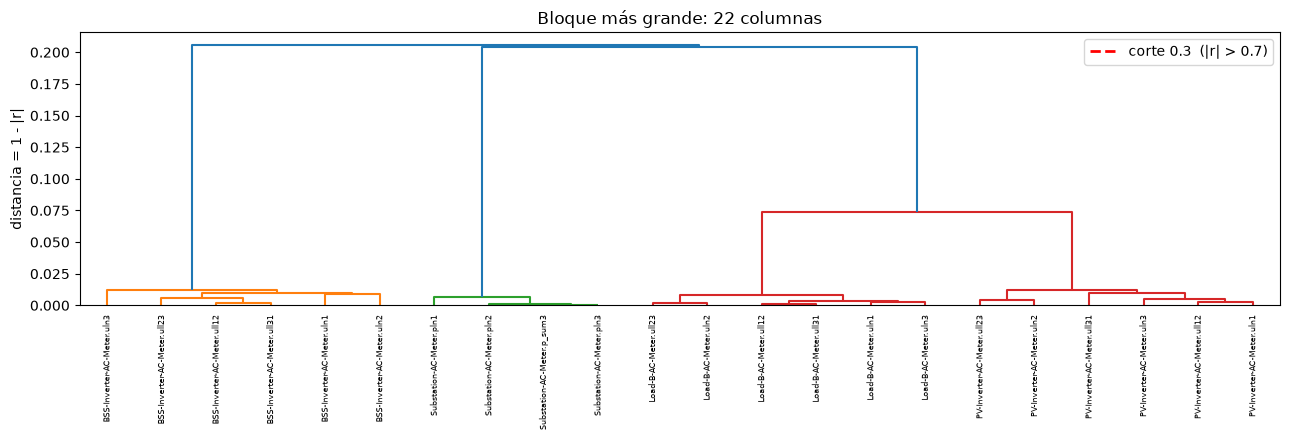

In [20]:
from scipy.cluster.hierarchy import dendrogram

# Repetimos la agrupación, pero solo con las columnas del bloque más grande.
subconjunto = X_entreno[columnas_mas_grande]
correlacion_sub = subconjunto.corr().abs().values
distancia_sub = 1 - correlacion_sub
np.fill_diagonal(distancia_sub, 0)
distancia_sub = (distancia_sub + distancia_sub.T) / 2
arbol_sub = linkage(squareform(distancia_sub, checks=False), method="average")

fig, eje = plt.subplots(figsize=(13, 4.5))
dendrogram(arbol_sub, labels=columnas_mas_grande, ax=eje, leaf_rotation=90, leaf_font_size=6)
eje.axhline(0.3, color="red", linestyle="--", linewidth=2, label="corte 0.3  (|r| > 0.7)")
eje.set_ylabel("distancia = 1 - |r|")
eje.set_title(f"Bloque más grande: {len(columnas_mas_grande)} columnas")
eje.legend()
plt.tight_layout()
plt.show()

varianza acumulada (primeras 5): [0.866 0.934 0.98  0.994 0.998]
componentes para el 95 %: 3


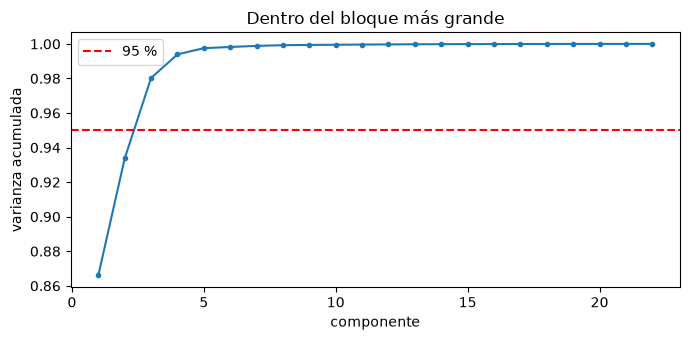

In [21]:
# PASO 5 - Cuántas componentes se queda cada bloque.
# Se estandariza primero porque PCA mide varianza, y las columnas vienen en
# unidades distintas (voltios, amperes, kW). Sin escalar, la de mayor escala
# dominaría la primera componente por unidad y no por información.
subconjunto_estandar = StandardScaler().fit_transform(subconjunto)
pca_bloque = PCA(random_state=42).fit(subconjunto_estandar)
# explained_variance_ratio_ dice qué porción de la varianza del bloque explica
# cada componente; cumsum() las acumula en orden.
varianza_acumulada = pca_bloque.explained_variance_ratio_.cumsum()

print("varianza acumulada (primeras 5):", np.round(varianza_acumulada[:5], 3))
print("componentes para el 95 %:", int(np.searchsorted(varianza_acumulada, 0.95) + 1))

fig, eje = plt.subplots(figsize=(7, 3.5))
eje.plot(range(1, len(varianza_acumulada) + 1), varianza_acumulada, marker="o", markersize=3)
eje.axhline(0.95, color="red", linestyle="--", label="95 %")
eje.set_xlabel("componente")
eje.set_ylabel("varianza acumulada")
eje.set_title("Dentro del bloque más grande")
eje.legend()
plt.tight_layout()
plt.show()

Las dos figuras muestran cosas distintas y conviene no mezclarlas:

- El **dendrograma** decide qué columnas van juntas: usa distancias. La línea roja queda por encima de todas las uniones, así que el bloque entra entero.
- El **gráfico de varianza** decide cuántas componentes se queda cada bloque: usa varianza. Acá el 95 % se alcanza con tres componentes porque las 22 columnas del bloque son casi la misma señal (86,6 % + 93,4 % + 98,0 %).

### Qué hace `block_pca()` en la evaluación real

Las celdas de arriba muestran **un solo fold**, para poder leer los bloques con nombre y apellido. En la evaluación LOSO, `src/reduce.py` repite todo siete veces:

1. Separar entrenamiento y prueba por escenario.
2. Imputar con la mediana del entrenamiento y descartar columnas de varianza nula.
3. Agrupar las columnas (pasos 1 a 4) y hacer PCA dentro de cada grupo (paso 5).
4. Concatenar las componentes de los 28 bloques: en este fold dan **43 columnas**; el promedio de los siete folds es **41**.
5. Entrenar el clasificador sobre esas columnas y predecir el escenario que quedó afuera.

El resultado medido es AUC **0,952** con Random Forest, la mejor de las ocho variantes que probamos.

Tres advertencias para interpretarlo:

1. El corte 0,70 es un hiperparámetro. Con 0,90 el AUC baja a 0,947 y con 0,95 a 0,939: los bloques se achican y la técnica se parece cada vez más al filtro de correlación.
2. El corte del 95 % es exigente: dos componentes llegan al 93,4 % de la varianza del bloque, así que la tercera es necesaria para pasarlo.
3. La especificidad en `S0` al umbral 0,5 baja a 0,815 contra 0,996 de `physical_corr`. Esa comparación es de calibración, no de capacidad: a la misma tasa de falsos positivos `block_pca` es mejor.

Por eso la receta que sigue en producción es `physical_corr`: usa unas 15 columnas reales, es interpretable y su especificidad es alta. `block_pca` queda como la mejor variante medida y como mejora pendiente.

### Cuántas columnas deja cada reducción

Cada fila es un camino distinto desde las 139 columnas hasta un conjunto más chico, medido sobre el mismo fold: entrenamiento con todos los escenarios menos `S0`.

Conviene mirar dos cosas a la vez: cuántas columnas deja cada método y en qué punto del camino se reducen. El filtro de correlación aparece dos veces y da resultados muy distintos —55 contra 15— porque en `physical_corr` recibe 25 columnas en lugar de 139. Lo que cambia no es el filtro: es lo que se le da de comer.

In [22]:
# Todas las reducciones en la misma tabla, sobre el mismo fold (S0 afuera).
# Para block_pca hay que sumar las componentes que retiene cada bloque al 95 %.
componentes_bloques = 0
for _, columnas_bloque in bloques.groupby(bloques):
    nombres_bloque = list(columnas_bloque.index)
    if len(nombres_bloque) > 1:
        bloque_escalado = StandardScaler().fit_transform(X_entreno[nombres_bloque])
        componentes_bloques += PCA(n_components=0.95, random_state=42).fit(bloque_escalado).n_components_
    else:
        componentes_bloques += 1

escalera_completa = pd.DataFrame(
    [
        ("sin reducir", X.shape[1], "las 139 tal cual"),
        ("corr", len(filtro_correlacion(X.loc[entreno_sin_s0])), "descarta una columna de cada par con |r| > 0,95"),
        ("physical_corr", len(columnas_s0), "dominio (139 -> 29) + promedio de freq (29 -> 25) + correlación"),
        ("pca", pca_95.n_components_, "PCA global, 95 % de la varianza total"),
        ("block_pca", componentes_bloques, "28 bloques, PCA al 95 % dentro de cada uno"),
        ("rfe", 15, "recursivo: de las 25 físicas elimina de a una hasta 15"),
    ],
    columns=["reducción", "columnas", "cómo llega"],
)
display(escalera_completa)

,reducción,columnas,cómo llega
0,sin reducir,139,las 139 tal cual
1,corr,55,"descarta una columna de cada par con |r| > 0,95"
2,physical_corr,15,dominio (139 -> 29) + promedio de freq (29 -> ...
3,pca,21,"PCA global, 95 % de la varianza total"
4,block_pca,43,"28 bloques, PCA al 95 % dentro de cada uno"
5,rfe,15,recursivo: de las 25 físicas elimina de a una ...


### Cuánto rinde cada reducción

La escalera contesta *cuántas* columnas quedan. Falta *cuánto rinde* cada camino, con las métricas de la evaluación LOSO y el mismo Random Forest en las seis filas.

Las dos columnas de conteo no coinciden y no es un error. La primera cuenta el fold que venimos usando (todo menos `S0`); la segunda promedia los ocho folds, y en cada uno el filtro de correlación y el corte de los bloques se reajustan con su propio entrenamiento. De ahí que `physical_corr` muestre 15 y 15,4, o `block_pca` 43 y 41,0: el número exacto de columnas depende de qué escenario queda afuera.

Cómo leerla:

- **`corr` sube el AUC con 55 columnas.** Descartar la mitad redundante alcanza para superar a las 139 originales (0,912).
- **`physical_corr` llega a 15 columnas y casi el mismo AUC**, con la mejor especificidad en `S0` de la tabla.
- **`pca` es la que más pierde** (0,873): el problema no es cuánta información retiene, sino que un árbol de decisión no puede cortar una mezcla de 139 columnas.
- **`block_pca` gana en AUC y en recall@5 %**, que es la métrica que importa si el costo de una falsa alarma es bajo.
- **`rfe (física)` confirma la receta sin mejorarla.** Elimina dentro de las 25 físicas hasta 15 y se acerca al AUC de `physical_corr`, conservando las columnas de `Profile.*`: la selección guiada por datos persigue la huella del escenario.

Ojo con el orden fino: 0,952 contra 0,943 es una diferencia **menor que la variación entre escenarios** de un mismo método. La tabla sirve para descartar caminos, no para coronar un ganador por la cuarta cifra.

In [23]:
# La tabla se lee de resultados/reduccion.csv: mismas 8 rondas LOSO, mismo Random Forest.
tabla_reduccion = pd.read_csv("resultados/reduccion.csv")

comparacion_reducciones = (
    tabla_reduccion[tabla_reduccion.model == "rf"]
    .set_index("reducer")
    .loc[["none", "corr", "physical_corr", "pca", "block_pca"]]
    .drop(columns="model")
    .rename(columns={
        "n_features": "columnas (promedio LOSO)",
        "auc_mean": "AUC",
        "recall_5": "recall@5%",
        "recall_1": "recall@1%",
        "spec_S0": "especificidad S0",
    })
)
comparacion_reducciones.insert(0, "reducción", ["sin reducir", "corr", "physical_corr", "pca", "block_pca"])
# El conteo de un solo fold ya está calculado en `escalera_completa`, en el mismo orden de filas.
# RFE no está en el CSV: se calcula acá, con el mismo protocolo (8 folds LOSO).
fila_rfe = pd.DataFrame(
    [{
        "reducción": "rfe (física)",
        "columnas (promedio LOSO)": loso_rfe.features.mean(),
        "AUC": loso_rfe.AUC.mean(),
        "recall@5%": loso_rfe.recall_5.mean(),
        "recall@1%": loso_rfe.recall_1.mean(),
        "especificidad S0": loso_rfe.especificidad_S0.dropna().iloc[0],
    }]
)
comparacion_reducciones = pd.concat([comparacion_reducciones, fila_rfe], ignore_index=True)

comparacion_reducciones.insert(1, "columnas (este fold)", escalera_completa["columnas"].to_numpy())
comparacion_reducciones = comparacion_reducciones.reset_index(drop=True)[
    [
        "reducción",
        "columnas (este fold)",
        "columnas (promedio LOSO)",
        "AUC",
        "recall@5%",
        "recall@1%",
        "especificidad S0",
    ]
]
display(comparacion_reducciones.round(3))

,reducción,columnas (este fold),columnas (promedio LOSO),AUC,recall@5%,recall@1%,especificidad S0
0,sin reducir,139,139.0,0.912,0.585,0.365,0.943
1,corr,55,55.0,0.941,0.652,0.449,0.718
2,physical_corr,15,15.4,0.943,0.637,0.489,0.996
3,pca,21,20.8,0.873,0.501,0.347,0.388
4,block_pca,43,41.0,0.952,0.752,0.490,0.815
5,rfe (física),15,15.0,0.948,0.668,0.545,1.000



## 3. Comparar cuatro modelos con block_pca

La escalera de reducciones mostró que `block_pca` es el que mejor ordena (AUC 0,952 con Random Forest). En esta sección mantenemos esa reducción fija y cambiamos el clasificador:

- **Random Forest** combina muchos árboles de decisión.
- **SVM con núcleo RBF** busca una frontera no lineal.
- **XGBoost** construye árboles en secuencia; cada uno corrige al anterior.
- **CatBoost** es otro boosting de árboles; usamos su manejo numérico y de nulos.

Todos usan la misma reducción `block_pca` y la misma evaluación LOSO. Los valores de configuración quedan fijos, visibles en `crear_modelo`; la búsqueda de hiperparámetros queda para la sección 3.2.

`block_pca` es el VARCLUS de la sección 2.4 empaquetado en `src/reduce.py`: agrupa columnas por correlación y hace un PCA por bloque. Como ya imputa y estandariza cada bloque, el modelo entrena directo sobre sus salidas, sin `crear_pipeline`.


In [ ]:

def loso_block_pca(nombre_modelo, guardar_detalle=False):
    """LOSO con block_pca: una fila por fold, con métricas de ranking y de umbral."""
    filas = []
    detalle = {}

    for retenido in ESCENARIOS:
        test = (escenario == retenido).to_numpy()
        train = ~test

        X_train, X_test = block_pca(X.loc[train], X.loc[test])
        y_train = y.loc[train]
        y_test = y.loc[test].to_numpy()

        modelo = crear_modelo(nombre_modelo)
        inicio = time.perf_counter()
        modelo.fit(X_train, y_train, sample_weight=pesos_balanceados(y_train))
        segundos = time.perf_counter() - inicio

        score = score_del_modelo(modelo, X_test)
        dos_clases = len(np.unique(y_test)) == 2
        pred = (score >= 0.5).astype(int)

        tn = int(((pred == 0) & (y_test == 0)).sum())
        fp = int(((pred == 1) & (y_test == 0)).sum())
        especificidad = tn / (tn + fp) if (tn + fp) else float("nan")

        filas.append(
            {
                "fold": retenido,
                "columnas": X_train.shape[1],
                "segundos": segundos,
                "AUC": roc_auc_score(y_test, score) if dos_clases else np.nan,
                "PR-AUC": average_precision_score(y_test, score) if dos_clases else np.nan,
                "recall@1%": recall_con_fpr(y_test, score, 0.01) if dos_clases else np.nan,
                "recall@5%": recall_con_fpr(y_test, score, 0.05) if dos_clases else np.nan,
                "recall@10%": recall_con_fpr(y_test, score, 0.10) if dos_clases else np.nan,
                "precisión@0.5": precision_score(y_test, pred, zero_division=0) if dos_clases else np.nan,
                "recall@0.5": recall_score(y_test, pred, zero_division=0) if dos_clases else np.nan,
                "F1@0.5": f1_score(y_test, pred, zero_division=0) if dos_clases else np.nan,
                "bal. acc": balanced_accuracy_score(y_test, pred) if dos_clases else np.nan,
                "espec. S0": especificidad if retenido == "S0" else np.nan,
            }
        )
        if guardar_detalle:
            detalle[retenido] = {"y_test": y_test, "score_test": score, "pred_test": pred}

    return pd.DataFrame(filas), detalle


In [ ]:

resultados_bp = {}
detalle_bp = {}
for nombre in ("rf", "svm", "xgb", "catboost"):
    resultados_bp[nombre], detalle_bp[nombre] = loso_block_pca(nombre, guardar_detalle=True)

tabla_por_fold_bp = pd.DataFrame(
    {nombre: resultados_bp[nombre].set_index("fold")["AUC"] for nombre in resultados_bp}
)
display(tabla_por_fold_bp.round(3))


In [ ]:

orden_modelos = ["rf", "svm", "xgb", "catboost"]


def media_folds(nombre, metrica):
    return resultados_bp[nombre].dropna(subset=["AUC"])[metrica].mean()


resumen_bp = pd.DataFrame(
    {
        "modelo": [ETIQUETAS[n] for n in orden_modelos],
        "AUC": [media_folds(n, "AUC") for n in orden_modelos],
        "PR-AUC": [media_folds(n, "PR-AUC") for n in orden_modelos],
        "recall@1%": [media_folds(n, "recall@1%") for n in orden_modelos],
        "recall@5%": [media_folds(n, "recall@5%") for n in orden_modelos],
        "recall@10%": [media_folds(n, "recall@10%") for n in orden_modelos],
        "precisión@0.5": [media_folds(n, "precisión@0.5") for n in orden_modelos],
        "recall@0.5": [media_folds(n, "recall@0.5") for n in orden_modelos],
        "F1@0.5": [media_folds(n, "F1@0.5") for n in orden_modelos],
        "bal. acc": [media_folds(n, "bal. acc") for n in orden_modelos],
        "espec. S0": [
            resultados_bp[n].loc[resultados_bp[n]["fold"] == "S0", "espec. S0"].iloc[0]
            for n in orden_modelos
        ],
        "seg/fold": [media_folds(n, "segundos") for n in orden_modelos],
    }
)
display(resumen_bp.round(3))



### Cómo leer la comparación

Sobre `block_pca`, los cuatro modelos ordenan parecido en AUC pero no en el punto de operación:

- **Random Forest gana en AUC (0,952)** y en recall@5 % (0,752): es el que más ataques detecta aceptando 5 % de falsas alarmas.
- **XGBoost gana en PR-AUC (0,953) y en F1 a umbral 0,5 (0,848)**, apenas por encima de CatBoost (F1 0,832).
- **CatBoost queda en el medio** (AUC 0,940): compite con XGBoost sin superarlo en ninguna métrica.
- **SVM se queda atrás** (AUC 0,853): con esta receta y estos datos, su frontera RBF separa peor.

Una lectura importante: la **especificidad en S0** baja para todos respecto de `physical_corr` (que daba 0,996 con RF). Con `block_pca`, RF deja pasar solo 0,815 del benigno no visto: gana sensibilidad, pero a costa de más falsas alarmas en el escenario limpio. Lo retomamos al final de la sección.



## 3.1 El escenario donde block_pca más aporta

`block_pca` no gana igual en todos lados. Comparando su AUC contra la línea base sin reducción (mismo Random Forest, `loso_base`), la mejora se concentra en dos escenarios:


In [ ]:

auc_sin_reducir = loso_base.set_index("fold")["AUC"]
auc_block_pca = resultados_bp["rf"].set_index("fold")["AUC"]

delta_bp = pd.DataFrame(
    {
        "AUC sin reducir": auc_sin_reducir,
        "AUC block_pca": auc_block_pca,
        "delta": auc_block_pca - auc_sin_reducir,
    }
).sort_values("delta", ascending=False)
display(delta_bp.round(3))



El salto más grande está en **S6: +0,119 de AUC** (de 0,858 a 0,977), seguido de S1alt (+0,104). En S2 la reducción prácticamente no cambia nada (−0,002).

S6 es el escenario del ataque MQTT. Con las 139 columnas sin reducir el AUC es 0,858; agrupar por correlación y comprimir por bloques lo lleva a 0,977. Es el mejor ejemplo de que la reducción, lejos de perder señal, la ordena. Por eso la interpretación del fold se hace acá.


In [ ]:

tabla_s6 = pd.DataFrame(
    {
        "modelo": [ETIQUETAS[n] for n in orden_modelos],
        "AUC": [resultados_bp[n].set_index("fold").loc["S6", "AUC"] for n in orden_modelos],
        "recall@5%": [resultados_bp[n].set_index("fold").loc["S6", "recall@5%"] for n in orden_modelos],
        "precisión@0.5": [resultados_bp[n].set_index("fold").loc["S6", "precisión@0.5"] for n in orden_modelos],
        "recall@0.5": [resultados_bp[n].set_index("fold").loc["S6", "recall@0.5"] for n in orden_modelos],
        "F1@0.5": [resultados_bp[n].set_index("fold").loc["S6", "F1@0.5"] for n in orden_modelos],
    }
)
display(tabla_s6.round(3))


In [ ]:

y_s6 = detalle_bp["rf"]["S6"]["y_test"]
pred_s6 = detalle_bp["rf"]["S6"]["pred_test"]
score_s6 = detalle_bp["rf"]["S6"]["score_test"]

ConfusionMatrixDisplay.from_predictions(
    y_s6, pred_s6, display_labels=["benigno", "ataque"], cmap="Blues"
)
plt.title("Matriz de confusión — S6, Random Forest sobre block_pca, umbral 0,5")
plt.show()

precision_bp, recall_bp, _ = precision_recall_curve(y_s6, score_s6)
fig, eje = plt.subplots(figsize=(5, 4))
eje.plot(recall_bp, precision_bp, label=f"PR-AUC = {average_precision_score(y_s6, score_s6):.3f}")
eje.set_xlabel("Recall")
eje.set_ylabel("Precisión")
eje.set_title("Curva precisión-recall — S6, RF sobre block_pca")
eje.legend()
plt.tight_layout()
plt.show()



## 3.2 Tuneo de hiperparámetros sin usar el escenario de prueba

El código de referencia de la cursada usa `GridSearchCV` y `RandomizedSearchCV`. Acá seguimos esa línea y **no** usamos optimización bayesiana: con LOSO anidado (8 folds externos) y cuatro modelos, una búsqueda bayesiana dispara el cómputo en Colab sin una ganancia esperable — la sección 3.1 original ya mostró que el margen de los hiperparámetros (~0,01 de recall) es menor que la variación entre escenarios (~0,13 de AUC).

Tuneamos **CatBoost**, que es el modelo nuevo y el que tiene más probabilidad de estar lejos de su mejor configuración. La grilla es chica a propósito: profundidad y learning rate, con 300 iteraciones fijas. El `block_pca` se reajusta en cada split interno, así que la validación interna nunca lo vio.


In [ ]:

parametros_catboost = [(4, 0.05), (4, 0.10), (6, 0.05), (6, 0.10)]
filas_tuneo = []

for retenido in ESCENARIOS:
    test = (escenario == retenido).to_numpy()
    train = ~test
    grupos_train = escenario.loc[train].to_numpy()

    # Validación interna: dejar un escenario con ataque afuera del entrenamiento externo.
    divisiones = []
    for i_train, i_valid in LeaveOneGroupOut().split(
        X.loc[train], y.loc[train], groups=grupos_train
    ):
        if len(np.unique(y.loc[train].iloc[i_valid])) == 2:
            divisiones.append((i_train, i_valid))

    mejor = None
    for profundidad, learning_rate in parametros_catboost:
        internos = []
        for i_train, i_valid in divisiones:
            X_tr, X_va = block_pca(X.loc[train].iloc[i_train], X.loc[train].iloc[i_valid])
            modelo = CatBoostClassifier(
                iterations=300,
                depth=profundidad,
                learning_rate=learning_rate,
                random_seed=42,
                verbose=0,
            )
            modelo.fit(
                X_tr,
                y.loc[train].iloc[i_train],
                sample_weight=pesos_balanceados(y.loc[train].iloc[i_train]),
            )
            score_interno = modelo.predict_proba(X_va)[:, 1]
            internos.append(recall_con_fpr(y.loc[train].iloc[i_valid], score_interno, 0.05))
        media = np.mean(internos)
        if mejor is None or media > mejor[1]:
            mejor = ((profundidad, learning_rate), media)

    (profundidad, learning_rate), interna = mejor
    X_tr, X_te = block_pca(X.loc[train], X.loc[test])
    modelo = CatBoostClassifier(
        iterations=300,
        depth=profundidad,
        learning_rate=learning_rate,
        random_seed=42,
        verbose=0,
    )
    modelo.fit(X_tr, y.loc[train], sample_weight=pesos_balanceados(y.loc[train]))
    score_test = modelo.predict_proba(X_te)[:, 1]
    y_test = y.loc[test].to_numpy()
    dos_clases = len(np.unique(y_test)) == 2

    filas_tuneo.append(
        {
            "fold": retenido,
            "profundidad": profundidad,
            "learning_rate": learning_rate,
            "recall@5% interno": round(interna, 3),
            "AUC test": roc_auc_score(y_test, score_test) if dos_clases else np.nan,
            "recall@5% test": recall_con_fpr(y_test, score_test, 0.05) if dos_clases else np.nan,
        }
    )

tabla_tuneo = pd.DataFrame(filas_tuneo)
display(tabla_tuneo.round(3))



### Cómo salió el tuneo

El tuneo no mejoró al CatBoost de configuración fija: **AUC medio 0,938 frente a 0,940**, y **recall@5 % 0,630 frente a 0,645**. La combinación ganadora cambia de fold en fold (profundidad 4 en S1, S2, S3 y S5; 6 en el resto), y el recall interno que reporta la búsqueda queda por encima del que después se obtiene en el escenario reservado — el mismo efecto que ya medimos con Random Forest en la sección 3.1 original.

La lectura es la misma que allá: **la configuración pesa menos que el escenario**. Para estos datos y esta reducción, los valores fijos ya estaban en el techo de la grilla. Es un resultado válido y se informa como tal: el tuneo confirma que no hay una combinación escondida en estos hiperparámetros que cambie el resultado.


## 4. Entender las métricas con un ejemplo

Tomamos un fold concreto: `S6`, Random Forest, receta reducida y umbral 0,5. El modelo da un puntaje a cada fila y, con ese umbral, decide si la marca como ataque o benigno.

La matriz de confusión cruza la respuesta real con la predicción:

| | Predijo ataque | Predijo benigno |
|---|---:|---:|
| **Era ataque** | TP: ataque detectado | FN: ataque que se escapó |
| **Era benigno** | FP: falsa alarma | TN: benigno reconocido |

Las métricas de esta sección se calculan a partir de esos cuatro conteos.


In [28]:
y_test = detalle_reducida["S6"]["y_test"]
pred_test = detalle_reducida["S6"]["pred_test"]
score_test = detalle_reducida["S6"]["score_test"]
exactitud_train = detalle_reducida["S6"]["exactitud_train"]

tn, fp, fn, tp = confusion_matrix(y_test, pred_test).ravel()
print(f"TP={tp}  FP={fp}  FN={fn}  TN={tn}")

exactitud = accuracy_score(y_test, pred_test)
precision = precision_score(y_test, pred_test)
recall = recall_score(y_test, pred_test)
especificidad = tn / (tn + fp)
f1 = f1_score(y_test, pred_test)
balanced = (recall + especificidad) / 2

display(
    pd.DataFrame(
        {
            "exactitud train": [exactitud_train],
            "exactitud test": [exactitud],
            "precision": [precision],
            "recall": [recall],
            "especificidad": [especificidad],
            "F1": [f1],
            "balanced accuracy": [balanced],
        },
        index=["S6 - Random Forest"],
    ).round(4)
)

print(classification_report(y_test, pred_test, target_names=["benigno", "ataque"], digits=3))
print("precisión del benigno:", round(tn / (tn + fn), 3))

TP=913  FP=18  FN=437  TN=432


,exactitud train,exactitud test,precision,recall,especificidad,F1,balanced accuracy
S6 - Random Forest,0.9986,0.7472,0.9807,0.6763,0.96,0.8005,0.8181


              precision    recall  f1-score   support

     benigno      0.497     0.960     0.655       450
      ataque      0.981     0.676     0.801      1350

    accuracy                          0.747      1800
   macro avg      0.739     0.818     0.728      1800
weighted avg      0.860     0.747     0.764      1800

precisión del benigno: 0.497


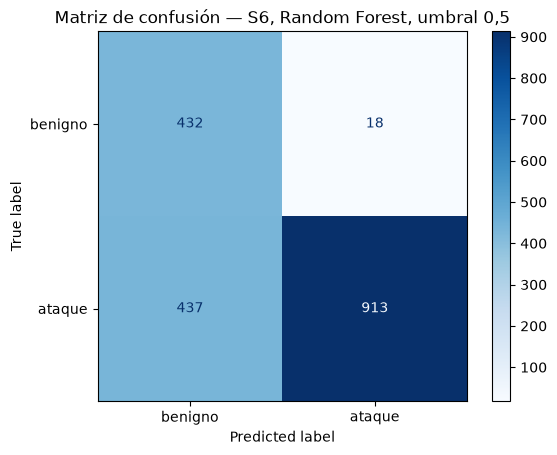

In [29]:
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_test, display_labels=["benigno", "ataque"], cmap="Blues"
)
plt.title("Matriz de confusión — S6, Random Forest, umbral 0,5")
plt.show()

In [30]:
print(
    classification_report(
        y_test, pred_test, target_names=["benigno", "ataque"], digits=3
    )
)

              precision    recall  f1-score   support

     benigno      0.497     0.960     0.655       450
      ataque      0.981     0.676     0.801      1350

    accuracy                          0.747      1800
   macro avg      0.739     0.818     0.728      1800
weighted avg      0.860     0.747     0.764      1800



### Qué nos dicen los resultados de S6

- **Recall = 0,676:** detecta 913 de los 1.350 ataques; se le escapan 437.
- **Precisión del ataque = 0,981:** de las 931 filas que marcó como ataque, 913 realmente eran ataques.
- **Especificidad = 0,960:** reconoce como benignas 432 de las 450 filas benignas; marca 18 como falsas alarmas.
- **Exactitud = 0,747:** parece razonable hasta compararla con la regla simple “decir ataque siempre”, que obtiene 0,750 porque el 75 % de S6 son ataques. En este fold, la exactitud del modelo es incluso un poco menor.

También hay dos detalles importantes:

- La **precisión del benigno** es 0,497: entre las filas que el modelo deja pasar como benignas, muchas en realidad son ataques (437 FN frente a 432 TN).
- La **precisión depende de cuántos ataques haya** en el conjunto evaluado. Como S6 tiene muchos ataques, puede ser alta aunque el modelo deje escapar una cantidad importante.
- La exactitud en entrenamiento es 0,999 y en prueba 0,747. Esa diferencia muestra que el resultado de entrenamiento no representa cómo se comporta el modelo con datos reservados.


### 4.1 ¿Qué pasa si cambiamos el umbral?

El umbral 0,5 convierte los puntajes en decisiones: si el puntaje alcanza o supera 0,5, la fila se marca como ataque. Ese valor es una regla de decisión, no una propiedad fija del modelo.

Si bajamos el umbral, más filas se marcan como ataques: suele subir el recall, pero también aumentan las falsas alarmas. La tabla muestra ese intercambio para S6.


In [31]:
filas = []
for umbral in (0.10, 0.30, 0.50, 0.70, 0.90):
    pred = (score_test >= umbral).astype(int)
    tn_u, fp_u, fn_u, tp_u = confusion_matrix(y_test, pred).ravel()
    filas.append(
        {
            "umbral": umbral,
            "TP": tp_u,
            "FP": fp_u,
            "FN": fn_u,
            "TN": tn_u,
            "recall": tp_u / (tp_u + fn_u) if (tp_u + fn_u) else np.nan,
            "especificidad": tn_u / (tn_u + fp_u) if (tn_u + fp_u) else np.nan,
            "precisión": tp_u / (tp_u + fp_u) if (tp_u + fp_u) else np.nan,
        }
    )

display(pd.DataFrame(filas).round(3))

,umbral,TP,FP,FN,TN,recall,especificidad,precisión
0,0.1,1290,159,60,291,0.956,0.647,0.890
1,0.3,1037,79,313,371,0.768,0.824,0.929
2,0.5,913,18,437,432,0.676,0.960,0.981
3,0.7,776,8,574,442,0.575,0.982,0.990
4,0.9,578,0,772,450,0.428,1.000,1.000


### 4.2 De dónde sale el recall de 0,676

La tabla muestra qué cambia al mover el umbral. El histograma ayuda a verlo: muestra cómo se distribuyen los puntajes del modelo para filas benignas y para ataques.


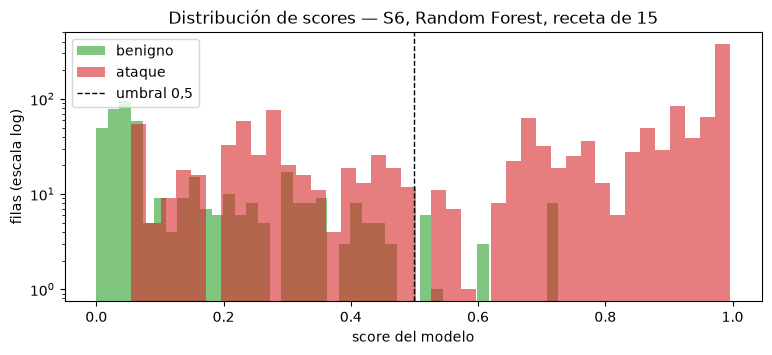

mediana benigno: 0.055
mediana ataque : 0.804
ataques con score < 0,5: 437 de 1350
benignos con score >= 0,5: 18 de 450


In [32]:
fig, eje = plt.subplots(figsize=(9, 3.5))
eje.hist(score_test[y_test == 0], bins=40, alpha=0.6, color="tab:green", label="benigno")
eje.hist(score_test[y_test == 1], bins=40, alpha=0.6, color="tab:red", label="ataque")
eje.axvline(0.5, color="black", ls="--", lw=1, label="umbral 0,5")
eje.set_xlabel("score del modelo")
eje.set_ylabel("filas (escala log)")
eje.set_yscale("log")
eje.set_title("Distribución de scores — S6, Random Forest, receta de 15")
eje.legend()
plt.show()

print("mediana benigno:", round(float(np.median(score_test[y_test == 0])), 3))
print("mediana ataque :", round(float(np.median(score_test[y_test == 1])), 3))
print(
    "ataques con score < 0,5:",
    int(((score_test < 0.5) & (y_test == 1)).sum()),
    "de",
    int((y_test == 1).sum()),
)
print(
    "benignos con score >= 0,5:",
    int(((score_test >= 0.5) & (y_test == 0)).sum()),
    "de",
    int((y_test == 0).sum()),
)

La mediana del puntaje es 0,055 para las filas benignas y 0,804 para los ataques. Sin embargo, algunos ataques reciben puntajes bajos: 437 quedan por debajo de 0,5 y se clasifican como benignos.

Por eso el AUC puede ser alto (0,932) y el recall con umbral 0,5 ser menor (0,676). El AUC evalúa cómo se ordenan los puntajes en todos los umbrales; el recall de esta tabla evalúa las decisiones tomadas con un umbral específico.


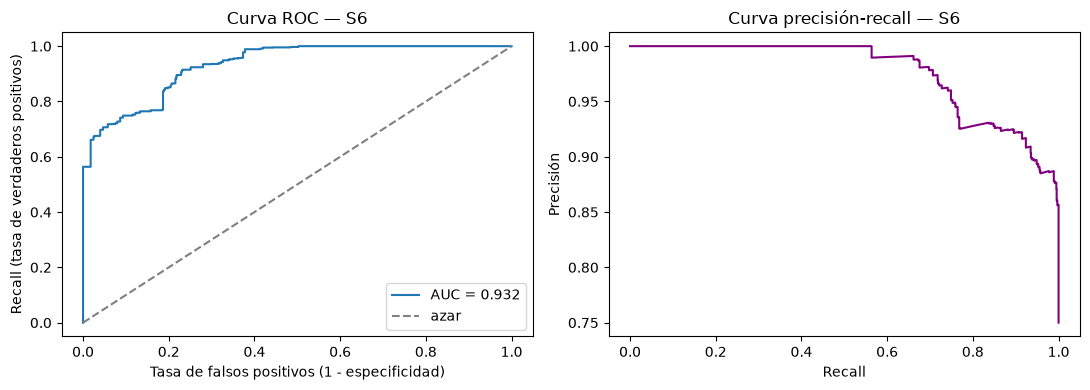

AUC: 0.932
recall aceptando 5 % de falsos positivos: 0.707
recall aceptando 1 % de falsos positivos: 0.564


In [33]:
fpr, tpr, umbrales = roc_curve(y_test, score_test)
auc_s6 = roc_auc_score(y_test, score_test)

precision_curva, recall_curva, _ = precision_recall_curve(y_test, score_test)

fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

ejes[0].plot(fpr, tpr, label=f"AUC = {auc_s6:.3f}")
ejes[0].plot([0, 1], [0, 1], "--", color="gray", label="azar")
ejes[0].set_title("Curva ROC — S6")
ejes[0].set_xlabel("Tasa de falsos positivos (1 - especificidad)")
ejes[0].set_ylabel("Recall (tasa de verdaderos positivos)")
ejes[0].legend()

ejes[1].plot(recall_curva, precision_curva, color="purple")
ejes[1].set_title("Curva precisión-recall — S6")
ejes[1].set_xlabel("Recall")
ejes[1].set_ylabel("Precisión")

plt.tight_layout()
plt.show()

print("AUC:", round(auc_s6, 3))
print("recall aceptando 5 % de falsos positivos:", round(recall_con_fpr(y_test, score_test, 0.05), 3))
print("recall aceptando 1 % de falsos positivos:", round(recall_con_fpr(y_test, score_test, 0.01), 3))

El **AUC** resume el orden de los puntajes: si elegimos al azar un ataque y un caso benigno, mide con qué frecuencia el ataque recibe un puntaje mayor. No fija un umbral y no significa “porcentaje de ataques detectados”.

El **recall@5 % FPR** responde otra pregunta: si permitimos que hasta el 5 % de las filas benignas se marquen como ataques, ¿qué proporción de los ataques detectamos? Ese 5 % limita la tasa de falsas alarmas; no garantiza una precisión superior al 95 %.


### 4.3 El fold S0 no tiene ataques

`S0` contiene solo filas benignas. Sin casos positivos no podemos calcular AUC, recall ni F1. Sí podemos medir la **especificidad**: qué proporción de las filas benignas el modelo reconoce correctamente.


In [34]:
y_s0 = detalle_reducida["S0"]["y_test"]
pred_s0 = detalle_reducida["S0"]["pred_test"]

tn, fp, fn, tp = confusion_matrix(y_s0, pred_s0).ravel()
print(f"S0 no tiene ataques -> TP={tp}, FN={fn}")
print("especificidad:", round(tn / (tn + fp), 3))
print("filas limpias marcadas como ataque:", int(fp), "de", len(y_s0))

S0 no tiene ataques -> TP=0, FN=0
especificidad: 0.996
filas limpias marcadas como ataque: 8 de 1798


Con la receta reducida, el modelo marca como benignas 1.790 de las 1.798 filas de `S0`.

No interpretemos la especificidad de 0,996 como prueba de transferencia a un escenario nuevo. Esa cifra depende en gran medida de `Profile.*`, cuyo rango en `S0` es 0 y queda fuera del rango visto en los escenarios de ataque; el informe lo cuantifica con una ablación (sección 4.12).


## 5. Del cuaderno a producción

Hasta acá entrenamos y evaluamos dentro del notebook. En producción el modelo no se reentrena: viaja como un archivo. `python -m src.production` guarda `modelos/supervised_reduced.joblib`, que contiene la receta de features, el umbral decidido en entrenamiento y el modelo ya entrenado.

Esta sección carga ese archivo y lo aplica a un CSV, sin volver a mirar las etiquetas.

In [35]:
import joblib
import subprocess

from src.features import detrend
from src.reduce import physical_features

try:
    paquete = joblib.load("modelos/supervised_reduced.joblib")
except Exception as error:
    # El bundle se guardó con otra versión de scikit-learn: lo regeneramos acá mismo.
    print("el bundle guardado no abre con esta versión:", error)
    print("lo regeneramos con src/production.py...")
    subprocess.run([sys.executable, "-m", "src.production", "--variant", "reduced"], check=True)
    paquete = joblib.load("modelos/supervised_reduced.joblib")

print("qué guarda el archivo:", list(paquete.keys()))
print("umbral:", paquete["threshold"], "| columnas esperadas:", len(paquete["columns"]))
print("primeras columnas:", paquete["columns"][:5])

qué guarda el archivo: ['pipeline', 'detrend', 'window', 'threshold', 'reduce', 'columns']
umbral: 0.5 | columnas esperadas: 15
primeras columnas: ['BSS-Inverter-AC-Meter.cos_phi1', 'Battery-SOC-Reference.soc_value', 'Battery-SOC-Reported.soc_value', 'Load-A-AC-Meter.cos_phi1', 'Load-A-AC-Meter.cos_phi2']


El paquete trae todo lo necesario para repetir el camino, en orden:

1. `detrend` y `window`: el rango móvil con el que se transformaron las variables.
2. `reduce` y `columns`: la receta física y las 15 columnas que sobrevivieron al filtro.
3. `pipeline`: imputado, escalado y modelo, ajustados juntos.
4. `threshold`: el punto de corte (0,5) con el que se leyeron todas las tablas de LOSO.

La probabilidad que devuelve el modelo se compara con ese umbral: si la supera, la fila se marca como ataque.

In [36]:
# 1. Un escenario nuevo, tal como llega: un CSV con una fila por segundo.
nuevo = pd.read_csv("datasets/datasetS6.csv").assign(scenario="objetivo")
matrices_nuevo = build_matrices(nuevo)

# 2. La misma transformación del entrenamiento, con las funciones que usa src/predict.py.
X_nuevo = detrend(
    matrices_nuevo.X,
    matrices_nuevo.scenario,
    method=paquete["detrend"],
    window=paquete["window"],
)
X_nuevo = physical_features(X_nuevo)
X_nuevo = X_nuevo[paquete["columns"]]

# 3. Probabilidad de ataque por fila y decisión con el umbral guardado.
probabilidad = paquete["pipeline"].predict_proba(X_nuevo)[:, 1]
alerta = (probabilidad > paquete["threshold"]).astype(int)

print("filas:", len(alerta), "| columnas usadas:", X_nuevo.shape[1])
print(f"alertas: {alerta.sum():,} ({alerta.mean():.1%})")

filas: 1800 | columnas usadas: 15
alertas: 1,351 (75.1%)


In [37]:
vista = pd.DataFrame(
    {
        "probabilidad": probabilidad,
        "alerta": np.where(alerta == 1, "sí", "no"),
        "etiqueta_real": np.where(matrices_nuevo.y_binary == 1, "ataque", "benigno"),
    }
)

print("alerta contra etiqueta real (S6 completo):")
display(pd.crosstab(vista["etiqueta_real"], vista["alerta"], margins=True))

# Desde el primer ataque: ahí se ve la probabilidad cruzar el umbral.
primer_ataque = int(np.flatnonzero(matrices_nuevo.y_binary.to_numpy() == 1)[0])
print(f"primeras filas de ataque (desde la fila {primer_ataque}):")
display(vista.iloc[primer_ataque : primer_ataque + 8].round(3))


alerta contra etiqueta real (S6 completo):


alerta,no,sí,All
etiqueta_real,,,
ataque,0,1350,1350
benigno,449,1,450
All,449,1351,1800


primeras filas de ataque (desde la fila 438):


,probabilidad,alerta,etiqueta_real
438,0.536,sí,ataque
439,0.688,sí,ataque
440,0.724,sí,ataque
441,0.975,sí,ataque
442,0.982,sí,ataque
443,0.982,sí,ataque
444,0.995,sí,ataque
445,0.995,sí,ataque


**Lectura.** El modelo acierta 1.799 de 1.800 filas: marca los 1.350 ataques y deja pasar 449 de las 450 benignas. Eso no es detección, es memoria: el bundle se entrenó con S6 adentro. El contraste con el fold que deja S6 afuera —recall 0,676 y 437 ataques sin detectar— mide cuánto de ese acierto depende de haber visto el escenario.

La sección demuestra el **circuito** —archivo, CSV, transformación, puntaje, umbral, alerta—, no el rendimiento. El rendimiento honesto es el de LOSO: AUC 0,943 y especificidad 0,996 en S0.

Y queda el problema operativo: con el umbral 0,5, 1.351 filas de media hora de operación llegan a revisión. Un operador no ve una probabilidad, ve una alerta. Por eso la conclusión separa dos cosas: el detector sirve como priorizador, y el umbral necesita calibración adaptativa.

Los bundles conviven: `supervised.joblib` (139 features) es la referencia y `supervised_reduced.joblib` (15) la variante elegida. El no supervisado en producción se demuestra en la sección de no supervisado.


## Conclusión

La validación cruzada aleatoria produce un resultado demasiado optimista porque filas vecinas y episodios relacionados quedan a ambos lados de la división, aunque los folds estén bien mezclados. LOSO es una evaluación más exigente, pero el AUC de 0,912 (base) o 0,943 (receta reducida) tampoco demuestra por sí solo que el modelo detecte ataques sin usar pistas temporales.

Hay que ser cautos por un motivo concreto: `Profile.*` aporta mucho al modelo y en `S0` queda fuera del rango visto en los escenarios de ataque. Lo que sí podemos sostener es que la receta reducida es más compacta y que evaluamos los modelos con un protocolo que separa escenarios.

**Para explicar el resultado en la defensa:**

1. La validación cruzada aleatoria de 8 folds da 0,9999, pero mezcla filas muy parecidas entre entrenamiento y prueba.
2. LOSO reserva un escenario entero; sus promedios son 0,912 con 139 variables y 0,943 con la receta reducida.
3. El recall en un punto de falsas alarmas y la especificidad ayudan a interpretar el uso operativo; no son lo mismo que AUC ni precisión.
4. `Profile.*` explica buena parte del resultado y está fuera de rango en `S0`, así que persiste una dependencia del momento y del escenario.
5. Por eso no afirmamos que este modelo haya probado una detección eléctrica independiente del tiempo.


## Revisión de esta sección frente a la consigna

La consigna pide selección de atributos, tratamiento del desbalanceo, validación cruzada e hiperparámetros; también pide métricas supervisadas por modelo y por predicción/clase, y un modelo supervisado mostrado en modo producción.

- **Incluido:** tres modelos (Random Forest, SVM y XGBoost), pesos que compensan el desbalanceo, evaluación LOSO, configuraciones fijas y métricas por modelo, por fold y por clase (matriz de confusión y reporte por clase en la sección 4).
- **Selección de atributos:** la receta física se compara con la importancia de Random Forest, con el filtro de correlación, con ACP (sección 2.3) y con ACP por bloques (sección 2.4). El ranking de importancia y la selección de las 15 variables se repiten dentro de cada fold, usando solo los datos de entrenamiento. Queda sin implementar RFE: la consigna nombra tres métodos alternativos y acá se cubren dos, con la medición de por qué el ACP global pierde.
- **Hiperparámetros:** se muestran las configuraciones de los tres modelos y se agrega una búsqueda con `GridSearchCV`, anidada dentro de LOSO, que optimiza recall@5 % FPR. El control muestra que las cuatro combinaciones de la grilla no superan a la configuración fija y que la diferencia es menor que la variación entre escenarios.
- **Modo producción:** la sección 5 carga el bundle guardado, lo aplica a un CSV y muestra el puntaje, el umbral y el conteo de alertas sin reentrenar.